In [1]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.naive_bayes import CategoricalNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    mutual_info_score
)

from preprocessing import load_adult, to_categories, save_predictions, save_model

In [2]:
#loading the dataset
trainDf, testDf = load_adult()
print(trainDf.shape)
print(testDf.shape)
trainDf.head()

(32561, 15)
(16281, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


In [3]:
#seperating features and labels
xTrain = trainDf.drop(columns=["income"])
yTrain = trainDf["income"]

xTest = testDf.drop(columns=["income"])
yTest = testDf["income"]

In [4]:
#preprocessing features
xTrainCat, xTestCat = to_categories(trainDf, testDf)

print(xTrainCat.shape)
print(xTestCat.shape)
xTrainCat.head()

(32561, 14)
(16281, 14)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,3,6,0,9,8,4,0,1,4,1,6,0,3,38
1,4,5,0,9,8,2,3,0,4,1,0,0,1,38
2,2,3,1,11,5,0,5,1,4,1,0,0,3,38
3,4,3,1,1,4,2,5,0,2,1,0,0,3,38
4,1,3,2,9,8,2,9,5,2,0,0,0,3,4


In [5]:
#checking min & max
for col in xTrainCat.columns:
    print(col, xTrainCat[col].min(), xTestCat[col].min(),
          xTrainCat[col].max(), xTestCat[col].max())

age 0 0 9 9
workclass 0 0 8 8
fnlwgt 0 0 9 9
education 0 0 15 15
education-num 0 0 9 9
marital-status 0 0 6 6
occupation 0 0 14 14
relationship 0 0 5 5
race 0 0 4 4
sex 0 0 1 1
capital-gain 0 0 9 9
capital-loss 0 0 9 9
hours-per-week 0 0 9 9
native-country 0 0 41 41


In [6]:
#training initial Naive Bayes model
nbModel = CategoricalNB()
nbModel.fit(xTrainCat, yTrain)

,"alpha alpha: float, default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"min_categories min_categories: int or array-like of shape (n_features,), default=NoneMinimum number of categories per feature.- integer: Sets the minimum number of categories per feature to `n_categories` for each features.- array-like: shape (n_features,) where `n_categories[i]` holds the minimum number of categories for the ith column of the input.- None (default): Determines the number of categories automatically from the training data... versionadded:: 0.24",None
Name,Type,Value
"category_count_ category_count_: list of arrays of shape (n_features,)Holds arrays of shape (n_classes, n_categories of respective feature)for each feature. Each array provides the number of samplesencountered for each class and category of the specific feature.",list,"[array([[5509.... 11.]]), array([[5.890... 0.0000e+00]]), array([[9.887... 0.0000e+00]]), array([[8.710..., 1.387e+03]]), ...]"
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[24720., 7841.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.28,-1.42]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_log_prob_ feature_log_prob_: list of arrays of shape (n_features,)Holds arrays of shape (n_classes, n_categories of respective feature)for each feature. Each array provides the empirical log probabilityof categories given the respective feature and class, ``P(x_i|y)``.",list,"[array([[-1.50...-6.48348954]]), array([[-3.73...-8.96826881]]), array([[-0.91...-8.96839619]]), array([[-3.34...-1.73354099]]), ...]"


In [7]:
#evaluating initial model
yPred = nbModel.predict(xTestCat)

initialAccuracy = accuracy_score(yTest, yPred)

print("Naive Bayes Accuracy:", initialAccuracy)
print(classification_report(yTest, yPred))
print(confusion_matrix(yTest, yPred))

Naive Bayes Accuracy: 0.8251335913027456
              precision    recall  f1-score   support

           0       0.92      0.84      0.88     12435
           1       0.60      0.77      0.68      3846

    accuracy                           0.83     16281
   macro avg       0.76      0.81      0.78     16281
weighted avg       0.85      0.83      0.83     16281

[[10463  1972]
 [  875  2971]]


In [8]:
#setting up grid search and cross validation
paramGrid = {
    "alpha": [0.1, 0.5, 1.0, 2.0, 5.0]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [9]:
#running grid search
grid = GridSearchCV(
    CategoricalNB(),
    paramGrid,
    cv=cv,
    scoring="accuracy",
    return_train_score=True
)

grid.fit(xTrainCat, yTrain)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",CategoricalNB()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.1, 0.5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scori

In [10]:
#grid search results
trainAcc = grid.cv_results_["mean_train_score"][grid.best_index_]
valAcc = grid.best_score_

print(f"Best alpha: {grid.best_params_['alpha']}")
print(f"Training accuracy: {trainAcc:.1%}")
print(f"Validation accuracy: {valAcc:.1%}")

Best alpha: 5.0
Training accuracy: 82.4%
Validation accuracy: 82.4%


In [11]:
#evaluating with grid and cross validation
yPredTuned = grid.predict(xTestCat)
testAcc = accuracy_score(yTest, yPredTuned)

print(f"Tuned Naive Bayes Test Accuracy: {testAcc:.1%}")

Tuned Naive Bayes Test Accuracy: 82.6%


In [12]:
#model result summary
results = pd.DataFrame({
    "Metric": [
        "Initial Test Accuracy",
        "Best Alpha",
        "Training Accuracy",
        "Cross-Validation Accuracy",
        "Tuned Test Accuracy"
    ],
    "Result": [
        f"{initialAccuracy:.2%}",
        grid.best_params_["alpha"],
        f"{trainAcc:.2%}",
        f"{valAcc:.2%}",
        f"{testAcc:.2%}"
    ]
})

display(results)

,Metric,Result
0,Initial Test Accuracy,82.51%
1,Best Alpha,5.0
2,Training Accuracy,82.43%
3,Cross-Validation Accuracy,82.39%
4,Tuned Test Accuracy,82.60%


In [13]:
#function to introduce label noise
def addLabelNoise(y, noiseLevel, randomState=42):
    rng = np.random.default_rng(randomState)
    yNoisy = y.to_numpy().copy()

    nFlip = int(len(yNoisy) * noiseLevel)
    flipIndices = rng.choice(len(yNoisy), size=nFlip, replace=False)

    yNoisy[flipIndices] = 1 - yNoisy[flipIndices]

    return yNoisy

In [14]:
#repeat noise experiments with different random seeds
noiseLevels = [0, 0.1, 0.2, 0.3, 0.4]
seeds = [0, 1, 2, 3, 4]
repeatResults = []
runs = []
for seed in seeds:
    for noiseLevel in noiseLevels:
        yTrainNoisy = addLabelNoise(
            yTrain, noiseLevel, randomState=seed
        )

        model = CategoricalNB(alpha=grid.best_params_["alpha"])
        model.fit(xTrainCat, yTrainNoisy)
        yPred = model.predict(xTestCat)
        runs.append((noiseLevel, seed, model.predict_proba(xTestCat)[:, 1]))
        if seed == 0: save_model("naiveBayes", noiseLevel, model)
        errorRate = 1 - accuracy_score(yTest, yPred)

        repeatResults.append({
            "Seed": seed,
            "Noise Level": noiseLevel,
            "Error Rate": errorRate
        })

repeatDf = pd.DataFrame(repeatResults)
save_predictions("naiveBayes", runs)
#average error across the five runs
summaryDf = repeatDf.groupby("Noise Level")["Error Rate"].agg(
    ["mean", "std"]
)

display(summaryDf)

,mean,std
Noise Level,,
0.0,0.174007,0.000000
0.1,0.189620,0.000950
0.2,0.198550,0.001044
0.3,0.205405,0.001366
0.4,0.211989,0.003491


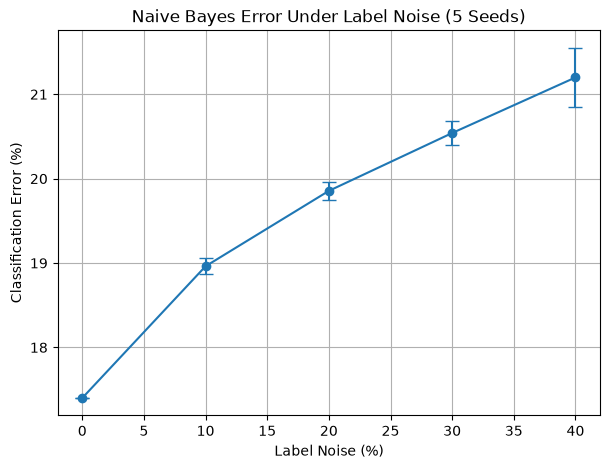

In [15]:
#plot average classification error with standard deviation
plt.figure(figsize=(7, 5))

plt.errorbar(
    summaryDf.index * 100,
    summaryDf["mean"] * 100,
    yerr=summaryDf["std"] * 100,
    marker="o",
    capsize=5
)

plt.xlabel("Label Noise (%)")
plt.ylabel("Classification Error (%)")
plt.title("Naive Bayes Error Under Label Noise (5 Seeds)")
plt.grid(True)
plt.show()

In [16]:
#combine two features
features = trainDf[["education", "marital-status"]]
jointFeature = features.astype(str).agg("_".join, axis=1)

#calculate mutual information with income
trueMI = mutual_info_score(jointFeature, yTrain)

print("Mutual Information:", trueMI)

Mutual Information: 0.1708636520478216


In [17]:
#probabilities under the Naive Bayes assumption
labels = pd.Series(np.asarray(yTrain))

feature1 = features["education"].reset_index(drop=True)
feature2 = features["marital-status"].reset_index(drop=True)

classProbs = labels.value_counts(normalize=True).sort_index()

educationProbs = pd.crosstab(
    labels, feature1, normalize="index"
)

maritalProbs = pd.crosstab(
    labels, feature2, normalize="index"
)

print("Class probabilities:")
print(classProbs)

print("Education probabilities:", educationProbs.shape)
print("Marital status probabilities:", maritalProbs.shape)

Class probabilities:
0    0.75919
1    0.24081
Name: proportion, dtype: float64
Education probabilities: (2, 16)
Marital status probabilities: (2, 7)


In [18]:
#calculate mutual information under Naive Bayes
pC = classProbs.to_numpy()
pE = educationProbs.to_numpy()
pM = maritalProbs.to_numpy()

#joint distribution under conditional independence
pJoint = pC[:, None, None] * pE[:, :, None] * pM[:, None, :]

#probability of each feature combination
pFeatures = pJoint.sum(axis=0)

#calculate Naive Bayes mutual information
denominator = pC[:, None, None] * pFeatures[None, :, :]

mask = pJoint > 0

nbMI = np.sum(
    pJoint[mask] * np.log(pJoint[mask] / denominator[mask])
)

#information loss
infoLoss = trueMI - nbMI

print("True Mutual Information:", trueMI)
print("Naive Bayes Mutual Information:", nbMI)
print("Information Loss:", infoLoss)

True Mutual Information: 0.1708636520478216
Naive Bayes Mutual Information: 0.15959156395237103
Information Loss: 0.011272088095450578


In [19]:
#calculate information loss for a given set of labels
def calculateInfoLoss(y):
    labels = pd.Series(np.asarray(y))
    jointFeature = features.astype(str).agg("_".join, axis=1)

    trueMI = mutual_info_score(jointFeature, labels)

    classProbs = labels.value_counts(normalize=True).sort_index()

    educationProbs = pd.crosstab(
        labels, features["education"].reset_index(drop=True),
        normalize="index"
    )

    maritalProbs = pd.crosstab(
        labels, features["marital-status"].reset_index(drop=True),
        normalize="index"
    )

    pC = classProbs.to_numpy()
    pE = educationProbs.to_numpy()
    pM = maritalProbs.to_numpy()

    pJoint = pC[:, None, None] * pE[:, :, None] * pM[:, None, :]
    pFeatures = pJoint.sum(axis=0)

    denominator = pC[:, None, None] * pFeatures[None, :, :]
    mask = pJoint > 0

    nbMI = np.sum(
        pJoint[mask] * np.log(pJoint[mask] / denominator[mask])
    )

    return trueMI - nbMI

In [20]:
#repeat information loss experiments with different seeds
infoRepeatResults = []

for seed in seeds:
    for noiseLevel in noiseLevels:
        yTrainNoisy = addLabelNoise(
            yTrain, noiseLevel, randomState=seed
        )

        infoLoss = calculateInfoLoss(yTrainNoisy)

        infoRepeatResults.append({
            "Seed": seed,
            "Noise Level": noiseLevel,
            "Information Loss": infoLoss
        })

infoRepeatDf = pd.DataFrame(infoRepeatResults)

infoSummaryDf = infoRepeatDf.groupby("Noise Level")[
    "Information Loss"
].agg(["mean", "std"])

display(infoSummaryDf)

,mean,std
Noise Level,,
0.0,0.011272,0.000000
0.1,0.001739,0.000501
0.2,0.000834,0.000578
0.3,0.000898,0.000343
0.4,0.001273,0.000145


In [21]:
#prepare the same two features for Naive Bayes
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

xTrainTwo = encoder.fit_transform(
    trainDf[["education", "marital-status"]]
)

xTestTwo = encoder.transform(
    testDf[["education", "marital-status"]]
)

#shift values so all categories are nonnegative
xTrainTwo = xTrainTwo.astype(int) + 1
xTestTwo = xTestTwo.astype(int) + 1

print(xTrainTwo.shape)
print(xTestTwo.shape)

(32561, 2)
(16281, 2)


In [22]:
#repeat two-feature experiments with different seeds
twoFeatureRepeatResults = []

for seed in seeds:
    for noiseLevel in noiseLevels:
        yTrainNoisy = addLabelNoise(
            yTrain, noiseLevel, randomState=seed
        )

        model = CategoricalNB(alpha=grid.best_params_["alpha"])
        model.fit(xTrainTwo, yTrainNoisy)

        yPred = model.predict(xTestTwo)
        errorRate = 1 - accuracy_score(yTest, yPred)

        twoFeatureRepeatResults.append({
            "Seed": seed,
            "Noise Level": noiseLevel,
            "Error Rate": errorRate
        })

twoFeatureRepeatDf = pd.DataFrame(twoFeatureRepeatResults)

twoFeatureSummaryDf = twoFeatureRepeatDf.groupby("Noise Level")[
    "Error Rate"
].agg(["mean", "std"])

display(twoFeatureSummaryDf)

,mean,std
Noise Level,,
0.0,0.177753,0.000000
0.1,0.177090,0.000227
0.2,0.177434,0.000296
0.3,0.177716,0.000120
0.4,0.181181,0.002727


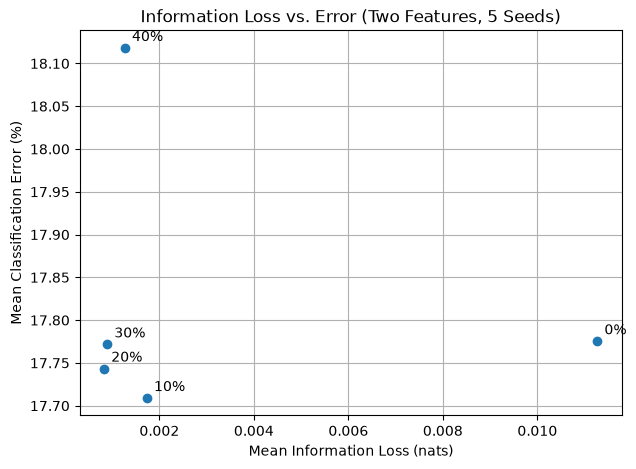

In [23]:
#compare average information loss and error
comparisonSummaryDf = pd.DataFrame({
    "Information Loss": infoSummaryDf["mean"],
    "Error Rate": twoFeatureSummaryDf["mean"]
})

plt.figure(figsize=(7, 5))

plt.scatter(
    comparisonSummaryDf["Information Loss"],
    comparisonSummaryDf["Error Rate"] * 100
)

for noiseLevel, row in comparisonSummaryDf.iterrows():
    plt.annotate(
        f"{noiseLevel * 100:.0f}%",
        (row["Information Loss"], row["Error Rate"] * 100),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Mean Information Loss (nats)")
plt.ylabel("Mean Classification Error (%)")
plt.title("Information Loss vs. Error (Two Features, 5 Seeds)")
plt.grid(True)
plt.show()

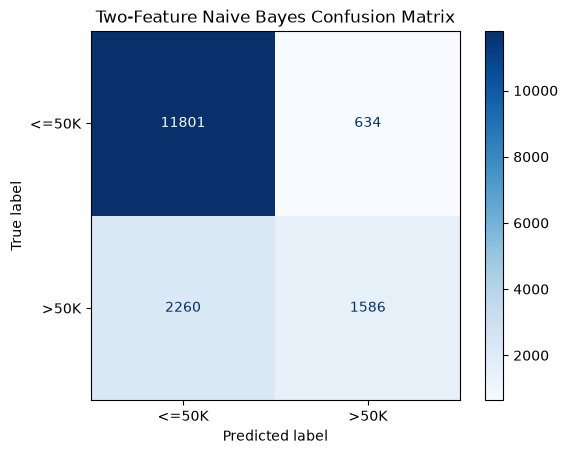

              precision    recall  f1-score   support

       <=50K       0.84      0.95      0.89     12435
        >50K       0.71      0.41      0.52      3846

    accuracy                           0.82     16281
   macro avg       0.78      0.68      0.71     16281
weighted avg       0.81      0.82      0.80     16281



In [24]:
#train two-feature model without label noise
model = CategoricalNB(alpha=grid.best_params_["alpha"])
model.fit(xTrainTwo, yTrain)

#predict on clean test data
yPred = model.predict(xTestTwo)

#display confusion matrix
cm = confusion_matrix(yTest, yPred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["<=50K", ">50K"]
).plot(cmap="Blues")

plt.title("Two-Feature Naive Bayes Confusion Matrix")
plt.show()

#classification report for two-feature model
print(classification_report(
    yTest,
    yPred,
    target_names=["<=50K", ">50K"]
))

In [25]:
#precision and recall under label noise (5 seeds)
metricResults = []

for seed in seeds:
    for noiseLevel in noiseLevels:
        yTrainNoisy = addLabelNoise(
            yTrain, noiseLevel, randomState=seed
        )

        model = CategoricalNB(alpha=grid.best_params_["alpha"])
        model.fit(xTrainTwo, yTrainNoisy)

        yPred = model.predict(xTestTwo)

        metricResults.append({
            "Seed": seed,
            "Noise Level": noiseLevel,
            "Precision >50K": precision_score(yTest, yPred, zero_division=0),
            "Recall >50K": recall_score(yTest, yPred, zero_division=0)
        })

metricDf = pd.DataFrame(metricResults)

metricSummaryDf = metricDf.groupby("Noise Level")[
    ["Precision >50K", "Recall >50K"]
].agg(["mean", "std"])

display(metricSummaryDf)

Precision >50K           Recall >50K          
                      mean       std        mean       std
Noise Level                                               
0.0               0.714414  0.000000    0.412376  0.000000
0.1               0.713576  0.000403    0.418201  0.001577
0.2               0.710360  0.003804    0.420281  0.003748
0.3               0.708464  0.002181    0.420905  0.003144
0.4               0.682811  0.022122    0.437441  0.018023